In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from itertools import combinations

RANDOM_STATE = 42
rng = np.random.default_rng(42)

In [3]:
DATASET_DIRECTORY = "../data/airbus-ship-detection"

FILEPATH = f"{DATASET_DIRECTORY}/train_ship_segmentations_v2.csv"

df = pd.read_csv(FILEPATH)
print("Количество записей:", len(df))
print("Количество изображений:", df["ImageId"].nunique())
print("Количество размеченных кораблей:", df["EncodedPixels"].notna().sum())
ship_df = df.dropna(subset=["EncodedPixels"])
print("Количество записей после удаления записей без кораблей:", len(ship_df))

Количество записей: 231723
Количество изображений: 192556
Количество размеченных кораблей: 81723
Количество записей после удаления записей без кораблей: 81723


In [4]:
def decode_rle(rle, height, width):
    mask = np.zeros(height*width, dtype=np.uint8)

    values = np.fromstring(rle, sep=" ",dtype=np.int64)
    starts = values[::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start+length] = 1

    return mask.reshape((height, width), order='F')

### Визуализация GT-масок

Выбираем изображение, содержащее не менее трёх кораблей, и декодируем соответствующие RLE-маски. Объединяем их в `instance_map`, где `0` обозначает фон, а каждому кораблю присваивается уникальный идентификатор `1, 2, ..., N`.

Для визуализации накладываем полупрозрачные instance-маски на исходное спутниковое изображение, скрывая фон.

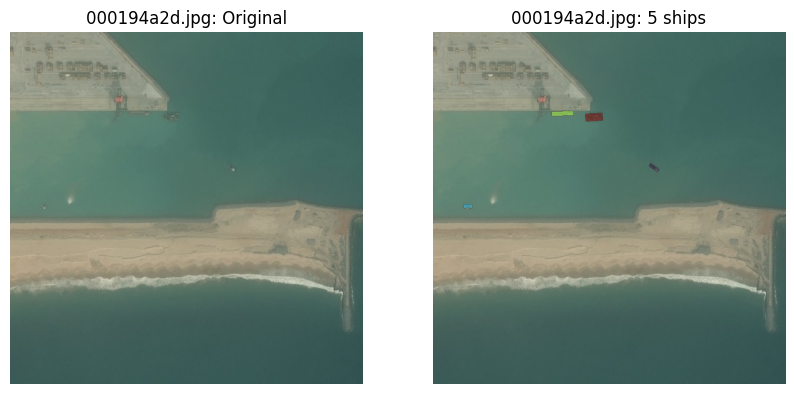

In [5]:
counts = ship_df.groupby("ImageId").size()
image_id = counts[counts >=3].index[0]

rles = ship_df.loc[
    ship_df["ImageId"] == image_id,
    "EncodedPixels"
]

h, w = 768, 768

instance_map = np.zeros((h, w), dtype=np.int32)

for instance_id, rle in enumerate(rles, start=1): # 0 - background, 1 - first ship, 2 - second ship....
    mask = decode_rle(rle, h, w)
    instance_map[mask == 1] = instance_id

image = plt.imread(f"{DATASET_DIRECTORY}/train_v2/{image_id}")

fig, axes = plt.subplots(1, 2, figsize = (10, 6))

masked_instances = np.ma.masked_equal(instance_map, 0)

axes[0].imshow(image)
axes[1].imshow(image)
axes[1].imshow(masked_instances, cmap="turbo", alpha=0.5)

axes[0].set_title(f"{image_id}: Original")
axes[1].set_title(f"{image_id}: {len(rles)} ships")
for ax in axes:
    ax.axis("off")

plt.show()

### Анализ площадей GT-масок

Площадь каждого корабля вычисляется как сумма длин последовательностей единиц в его RLE-представлении, без декодирования полной маски.

In [6]:
def rle_area(rle):
    values = np.fromstring(rle, sep=" ", dtype = np.int64)
    lengths = values[1::2]
    return lengths.sum()

ship_df["Area"] = ship_df["EncodedPixels"].apply(rle_area)

ship_df["Area"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])



count    81723.000000
mean      1567.402849
std       2842.081203
min          2.000000
1%          18.000000
5%          35.000000
25%        111.000000
50%        408.000000
75%       1550.000000
95%       7521.000000
99%      14942.000000
max      25904.000000
Name: Area, dtype: float64

Результаты анализа:
- Всего размечено 81 723 корабля.
- Площади варьируются от 2 до 25 904 пикселей.
- Медианная площадь — 408 пикселей, средняя — 1 567 пикселей.
- 5% кораблей имеют площадь не более 35 пикселей, 25% — не более 111 пикселей.

Распределение сильно скошено вправо: преобладают небольшие корабли, но присутствуют и значительно более крупные объекты.

Вывод: при выборе параметра `min_area` необходимо учитывать маленькие корабли, чтобы фильтрация шума не приводила к удалению корректных объектов. Окончательное значение порога будет определяться экспериментально.

### Анализ расстояний между GT-масками и связности объектов

Для выбранного изображения вычисляем минимальные евклидовы расстояния между всеми парами кораблей с помощью Distance Transform.

Затем применяем алгоритм Connected Components Labeling (CCL) к объединённой бинарной маске, используя 4-connectivity и 8-connectivity, и сравниваем количество найденных компонент с количеством GT-кораблей.

In [7]:
masks = [decode_rle(rle, h, w).astype(bool) for rle in rles]

for i, j in combinations(range(len(masks)), 2):
    distance_map = cv2.distanceTransform(
        (~masks[i]).astype(np.uint8),
        cv2.DIST_L2,
        cv2.DIST_MASK_PRECISE
    )

    distance = distance_map[masks[j]].min()

    print(f"Ships {i+1} and {j+1}: {distance:.2f} px")

binary_mask = (instance_map > 0).astype(np.uint8)

num_labels8, labels8 = cv2.connectedComponents(
    binary_mask,
    connectivity=8
)

num_labels4, labels4 = cv2.connectedComponents(
    binary_mask,
    connectivity=4
)

print("\nКоличество GT-кораблей:", len(rles))
print("Количество компонент CCL-8", num_labels8 - 1)
print("Количество компонент CCL-4:", num_labels4 - 1)

Ships 1 and 2: 394.06 px
Ships 1 and 3: 197.20 px
Ships 1 and 4: 401.91 px
Ships 1 and 5: 139.45 px
Ships 2 and 3: 259.86 px
Ships 2 and 4: 1.41 px
Ships 2 and 5: 307.03 px
Ships 3 and 4: 270.56 px
Ships 3 and 5: 26.00 px
Ships 4 and 5: 317.20 px

Количество GT-кораблей: 5
Количество компонент CCL-8 4
Количество компонент CCL-4: 5


Для пары кораблей 2 и 4 видно, что их пиксели соприкасаются по диагонали. Следовательно, при применении алгоритма поиска компонент связности (Connected Components Labeling) с 8-connectivity получим, что CCL обьединит 2 и 4 корабли в один компонент. А при использовании 4-connectivity диагонального соприкосновения недостаточно для обьединения масок.

Однако 4-connectivity может разделять и отдельные части одного корабля, соединённые только по диагонали. Поэтому выбор типа связности требует дальнейшего анализа на всём датасете.

На текущем этапе 4-connectivity рассматривается как потенциально более подходящий вариант, но окончательный выбор будет сделан после сравнения результатов.

In [8]:
grouped = ship_df.groupby("ImageId")["EncodedPixels"]

results = []

for image_id, rles in grouped:
    instance_map = np.zeros((h, w), dtype=np.int32)
    masks = [decode_rle(rle, h, w).astype(bool) for rle in rles]
    
    for instance_id, mask in enumerate(masks, start=1):
        instance_map[mask == 1] = instance_id

    binary_mask = (instance_map > 0).astype(np.uint8)

    num_labels8, _ = cv2.connectedComponents(
    binary_mask,
    connectivity=8
    )

    num_labels4, _ = cv2.connectedComponents(
        binary_mask,
        connectivity=4
    )

    min_distance = np.nan

    if len(masks) > 1:
        min_distance = np.inf

        for i in range(len(masks) - 1):
            distance_map = cv2.distanceTransform(
                (~masks[i]).astype(np.uint8),
                cv2.DIST_L2,
                cv2.DIST_MASK_PRECISE
            )

            for j in range(i + 1, len(masks)):
                distance = distance_map[masks[j]].min()
                min_distance = min(min_distance, distance)

            if min_distance == 0:
                break

    results.append({
        "ImageId": image_id,
        "GT": len(masks),
        "CCL4": num_labels4 - 1,
        "CCL8": num_labels8 - 1,
        "MinDistance": min_distance
    })

results_df = pd.DataFrame(results)


In [9]:
results_df.head()

,ImageId,GT,CCL4,CCL8,MinDistance
0,000155de5.jpg,1,1,1,NaN
1,000194a2d.jpg,5,5,4,1.414214
2,00021ddc3.jpg,9,5,4,1.000000
3,0002756f7.jpg,2,2,1,1.000000
4,00031f145.jpg,1,1,1,NaN


In [10]:
results_df['CCL4=CCL8'] = results_df['CCL4'] == results_df['CCL8']
results_df['CCL4_match'] = results_df['GT'] == results_df['CCL4']
results_df['CCL8_match'] = results_df['GT'] == results_df['CCL8']

summary = results_df.agg({
    "GT": ["sum", "mean"],
    "CCL4": ["sum", "mean"],
    "CCL8": ["sum", "mean"],
    "CCL4=CCL8": ["sum", "mean"],
    "CCL4_match": ["sum", "mean"],
    "CCL8_match": ["sum", "mean"],
    "MinDistance": ["min", "max", "mean", "median"]
})

summary

,GT,CCL4,CCL8,CCL4=CCL8,CCL4_match,CCL8_match,MinDistance
sum,81723.000000,75517.000000,73591.000000,41119.000000,38229.000000,37676.000000,NaN
mean,1.920364,1.774532,1.729274,0.966233,0.898322,0.885328,142.120534
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
max,NaN,NaN,NaN,NaN,NaN,NaN,924.801086
median,NaN,NaN,NaN,NaN,NaN,NaN,61.004099


В среднем на изображении, содержащем корабли, размечено 1.92 корабля. CCL-4 находит в среднем 1.77 связных компоненты, CCL-8 — 1.73.

Количество найденных компонент у CCL-4 и CCL-8 совпадает в 96.6% случаев. При этом CCL-4 воспроизводит количество GT-кораблей в 89.8% случаев, а CCL-8 — в 88.5%.

Таким образом, CCL-4 показывает несколько лучшие предварительные результаты. Однако совпадение количества компонент не гарантирует их соответствия отдельным GT-маскам. Для окончательного выбора алгоритма необходимо дополнительно исследовать ошибки oversegmentation и undersegmentation.

Среднее минимальное расстояние между кораблями на изображениях с несколькими объектами составляет 142 пикселя, медианное — 61 пиксель. Минимальное наблюдаемое расстояние составляет 1 пиксель, максимальное — 924 пикселя.

Значительное различие между средним и медианным расстояниями указывает на асимметричность распределения. Наличие близко расположенных кораблей подтверждает необходимость исследования ошибок объединения объектов при использовании CCL.

In [11]:
for connectivity in [4, 8]:
    col = f"CCL{connectivity}"

    print(f"CCL-{connectivity}")
    print("Совпадений:", (results_df[col] == results_df["GT"]).sum())
    print("Меньше компонент, чем GT:", (results_df[col] < results_df["GT"]).sum())
    print("Больше компонент, чем GT:", (results_df[col] > results_df["GT"]).sum())
    print()

CCL-4
Совпадений: 38229
Меньше компонент, чем GT: 4186
Больше компонент, чем GT: 141

CCL-8
Совпадений: 37676
Меньше компонент, чем GT: 4799
Больше компонент, чем GT: 81



Для обоих вариантов CCL преобладает ситуация, когда количество найденных компонент меньше количества GT-кораблей, что может свидетельствовать об объединении нескольких кораблей в одну компоненту (undersegmentation).

CCL-4: 4186 случаев с меньшим количеством компонент и 141 случай с большим.

CCL-8: 4799 случаев с меньшим количеством компонент и 81 случай с большим.

CCL-4 реже объединяет отдельные объекты, однако чаще разделяет их на дополнительные компоненты, чем CCL-8.

Таким образом, CCL-4 показывает лучшие результаты по совпадению количества компонент с GT, но оба варианта значительно чаще недооценивают количество объектов, чем переоценивают его. Это указывает на потенциальную необходимость применения алгоритмов разделения соприкасающихся кораблей, например Distance Transform + Watershed.

При этом расхождения по количеству компонент не позволяют однозначно определить ошибки undersegmentation и oversegmentation. Для их точной оценки необходимо сопоставить найденные компоненты с отдельными GT-масками.

---

### Анализ минимальных расстояний между GT-масками

In [12]:
results_df["MinDistance"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    15452.000000
mean       142.120534
std        178.387602
min          1.000000
1%           1.000000
5%           1.000000
25%          1.000000
50%         61.004099
75%        237.528404
95%        526.047299
99%        675.647114
max        924.801086
Name: MinDistance, dtype: float64

Анализ проведён для 15 452 изображений, содержащих два и более корабля.

На 25% этих изображений минимальное расстояние между GT-масками составляет всего 1 пиксель, что свидетельствует о наличии соприкасающихся кораблей.

Медианное минимальное расстояние составляет 61 пиксель, среднее — 142.12 пикселя. Значительное превышение среднего над медианой указывает на асимметричное распределение с длинным правым хвостом.

Вывод: в датасете присутствует существенное количество близко расположенных и соприкасающихся кораблей, поэтому одного CCL может быть недостаточно для корректного выделения отдельных экземпляров. Необходимо исследовать дополнительные методы разделения объектов.

Для 25% компонент в датасете расстояние между компонентами составляет всего 1 пиксель. В среднем расстояние составляет 61 пиксель. 

---

### Анализ соприкосновений GT-масок

In [13]:
distances = results_df["MinDistance"].dropna()

print("Пересечение масок:", (distances == 0).sum())
print("Горизонтальное/вертикальное соседство:", (distances == 1).sum())
print("Диагональное соседство:", np.isclose(distances, np.sqrt(2)).sum())
print("Расстояние <= 5 px:", (distances <= 5).sum())

Пересечение масок: 0
Горизонтальное/вертикальное соседство: 4292
Диагональное соседство: 557
Расстояние <= 5 px: 5364


На 4292 изображениях (27.8%) минимальное расстояние между кораблями составляет 1 пиксель, что свидетельствует об их горизонтальном или вертикальном соприкосновении. В таких случаях и CCL-4, и CCL-8 объединяют соприкасающиеся области в одну связную компоненту.

На 557 изображениях (3.6%) минимальное расстояние составляет $\sqrt{2}$ пикселя, что соответствует диагональному соприкосновению. При использовании 8-connectivity такие области считаются связанными, тогда как 4-connectivity не объединяет их только на основании диагонального соседства.

Всего на 5364 изображениях (34.7%) минимальное расстояние между кораблями не превышает 5 пикселей.

Вывод: значительная доля изображений содержит близко расположенные или соприкасающиеся корабли. При этом переход от 8-connectivity к 4-connectivity позволяет избежать некоторых случаев ошибочного объединения, но не решает проблему горизонтального и вертикального соприкосновения. Это дополнительно обосновывает необходимость исследования методов разделения объектов, в частности Distance Transform + Watershed.

---

### Анализ ошибок Undersegmentation и Oversegmentation

Для более точной оценки работы CCL недостаточно сравнивать количество найденных компонент с количеством GT-кораблей, поскольку ошибки объединения и разделения объектов могут компенсировать друг друга.

Выберем изображение, на котором количество компонент CCL-4 отличается от GT, и построим соответствие между отдельными GT-масками и найденными компонентами.

На основе полученных соответствий определим два типа ошибок:

- **Undersegmentation** — одна компонента CCL объединяет несколько GT-кораблей.
- **Oversegmentation** — одна GT-маска разделяется на несколько компонент CCL.

In [14]:
image_id = results_df.loc[
    results_df["CCL4"] != results_df["GT"],
    "ImageId"
].iloc[0]

rles = ship_df.loc[
    ship_df["ImageId"] == image_id,
    "EncodedPixels"
]

masks = [decode_rle(rle, h, w).astype(bool) for rle in rles]

binary_mask = np.zeros((h, w), dtype=np.uint8)

for mask in masks:
    binary_mask[mask] = 1

num_labels, labels = cv2.connectedComponents(
    binary_mask,
    connectivity=4
)

gt_to_components = {}
component_to_gt = {i: [] for i in range(1, num_labels)}

for gt_id, mask in enumerate(masks, start=1):
    component_ids = np.unique(labels[mask])
    component_ids = component_ids[component_ids != 0]

    gt_to_components[gt_id] = component_ids.tolist()

    for component_id in component_ids:
        component_to_gt[component_id].append(gt_id)

oversegmentation = {
    gt_id: components
    for gt_id, components in gt_to_components.items()
    if len(components) > 1
}

undersegmentation = {
    component_id: gt_ids
    for component_id, gt_ids in component_to_gt.items()
    if len(gt_ids) > 1
}

print("Oversegmentation:", oversegmentation)
print("Undersegmentation:", undersegmentation)

Oversegmentation: {}
Undersegmentation: {3: [3, 4, 7], 5: [1, 2, 9]}


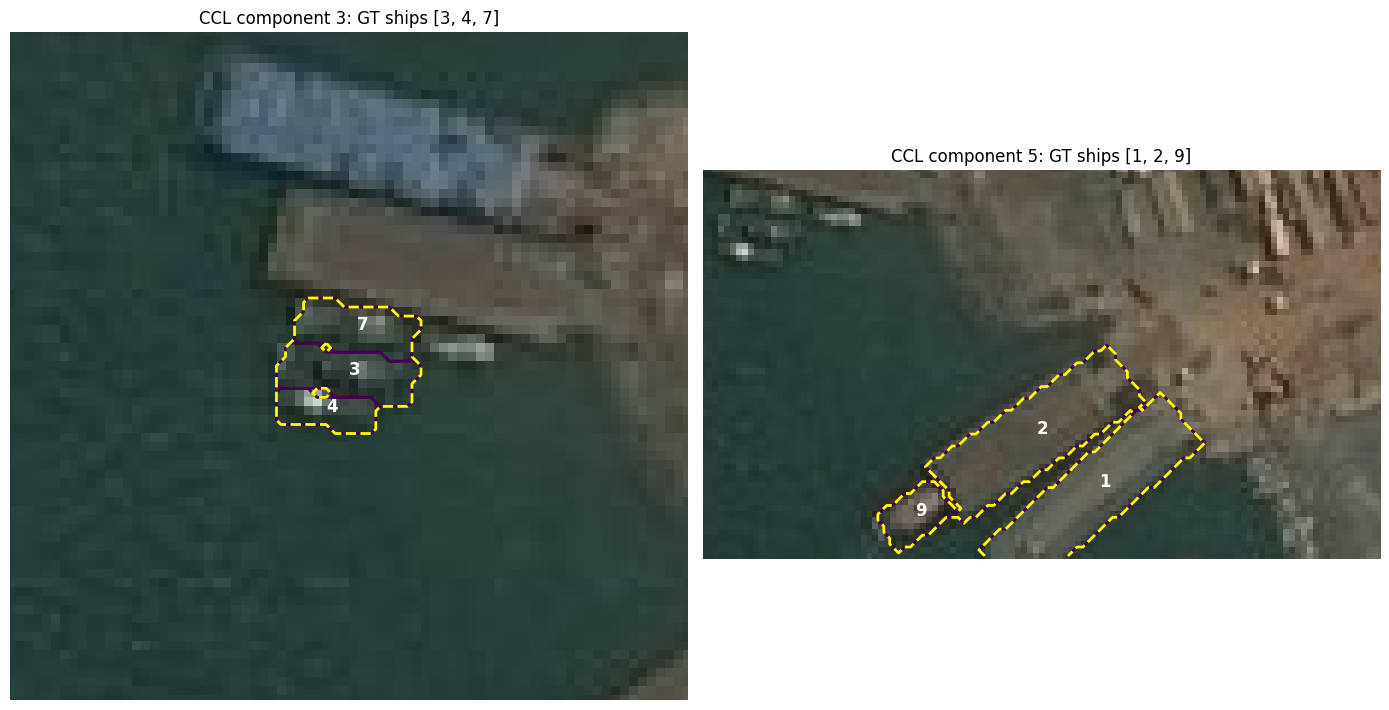

In [15]:
image = plt.imread(f"{DATASET_DIRECTORY}/train_v2/{image_id}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, component_id in zip(axes, [3, 5]):
    gt_ids = component_to_gt[component_id]

    ax.imshow(image)

    #Контуры отдельных GT-кораблей
    for gt_id in gt_ids:
        mask = masks[gt_id - 1]

        ax.contour(mask, levels=[0.5], linewidths=2)

        y, x = np.where(mask)
        ax.text(x.mean(), y.mean(), str(gt_id),
                color="white", fontsize=12, fontweight="bold")

    #Общий контур компоненты CCL
    component_mask = labels == component_id

    ax.contour(component_mask, levels=[0.5],
               colors="yellow", linewidths=2, linestyles="dashed")

    #Увеличиваем область компоненты
    y, x = np.where(component_mask)
    padding = 30

    ax.set_xlim(max(0, x.min() - padding), min(w, x.max() + padding))
    ax.set_ylim(min(h, y.max() + padding), max(0, y.min() - padding))

    ax.set_title(f"CCL component {component_id}: GT ships {gt_ids}")
    ax.axis("off")

plt.tight_layout()
plt.show()

На выбранном изображении алгоритм CCL-4 объединил **6 отдельных GT-масок в 2 связные компоненты**: по три корабля в каждой. Это свидетельствует о наличии ошибок undersegmentation.

Ошибок oversegmentation на данном изображении не выявлено.

Далее проведём аналогичный анализ на всём датасете для CCL-4 и CCL-8, чтобы оценить частоту возникновения ошибок undersegmentation и oversegmentation и определить наиболее подходящий тип связности для дальнейшей постобработки.

In [17]:
grouped = ship_df.groupby("ImageId")["EncodedPixels"]

errors = []

for image_id, rles in grouped:

    masks = [decode_rle(rle, h, w).astype(bool) for rle in rles]

    binary_mask = np.zeros((h, w), dtype=np.uint8)

    for mask in masks:
        binary_mask[mask] = 1

    result = {"ImageId": image_id}

    for connectivity in [4,8]:
        num_labels, labels = cv2.connectedComponents(
            binary_mask,
            connectivity=connectivity
        )

        gt_to_components = {}
        component_to_gt = {i: [] for i in range(1, num_labels)}

        for gt_id, mask in enumerate(masks, start=1):
            component_ids = np.unique(labels[mask])
            component_ids = component_ids[component_ids != 0]

            gt_to_components[gt_id] = component_ids.tolist()

            for component_id in component_ids:
                component_to_gt[component_id].append(gt_id)

        oversegmentation = {
            gt_id: components
            for gt_id, components in gt_to_components.items()
            if len(components) > 1
        }

        undersegmentation = {
            component_id: gt_ids
            for component_id, gt_ids in component_to_gt.items()
            if len(gt_ids) > 1
        }

        result[f"CCL{connectivity}_over"] = len(oversegmentation)
        result[f"CCL{connectivity}_under"] = len(undersegmentation)

    errors.append(result)

errors_df = pd.DataFrame(errors)


In [23]:
errors_df.drop(columns=["ImageId"]).agg(['sum', 'mean', 'max'])

,CCL4_over,CCL4_under,CCL8_over,CCL8_under
sum,453.000000,5437.000000,207.000000,6170.000000
mean,0.010645,0.127761,0.004864,0.144985
max,6.000000,5.000000,6.000000,6.000000


In [26]:
for connectivity in [4, 8]:
    over = errors_df[f"CCL{connectivity}_over"]
    under = errors_df[f"CCL{connectivity}_under"]

    print(f"CCL-{connectivity}:")
    print(f"Oversegmentation: {(over > 0).mean() * 100:.2f}%")
    print(f"Undersegmentation: {(under > 0).mean() * 100:.2f}%")
    print(f"Any error: {((over > 0) | (under > 0)).mean() * 100:.2f}%")

CCL-4:
Oversegmentation: 0.82%
Undersegmentation: 10.09%
Any error: 10.29%
CCL-8:
Oversegmentation: 0.34%
Undersegmentation: 11.39%
Any error: 11.49%


### Сравнение ошибок CCL-4 и CCL-8

Анализ объединённых GT-масок всего датасета показал, что при использовании обоих вариантов CCL преобладают ошибки *undersegmentation*.

Для CCL-4 ошибки объединения GT-масок обнаружены на **10.09% изображений**, а ошибки разделения — на **0.82%**. Для CCL-8 соответствующие показатели составляют **11.39%** и **0.34%**.

Общая доля изображений с хотя бы одной ошибкой составляет **10.29% для CCL-4** и **11.49% для CCL-8**.

Таким образом, CCL-4 показывает лучшие результаты по доле изображений без ошибок объединения и разделения GT-масок, хотя несколько чаще допускает *oversegmentation*.

**CCL-4 можно рассматривать как основной вариант для baseline постобработки.**